# Data Understanding & EDA
## Supply Chain Performance & Decision Intelligence

**Goal of this notebook:** Validate the dataset before building the actual KPI/index logic — check structure, completeness, join-key consistency, and distributions.

**Data source:** Dzalbs, I. & Kalganova, T. (2019). *Supply Chain Logistics Problem Dataset (Version 2)*. Brunel University London, Figshare.
https://brunel.figshare.com/articles/dataset/Supply_Chain_Logistics_Problem_Dataset/7558679

Related publication: Dzalbs, I., & Kalganova, T. (2020). Accelerating supply chains with Ant Colony Optimization across a range of hardware solutions. *Computers & Industrial Engineering*, 147, 106610.

## 1. Setup & loading the raw data

In [15]:
import pandas as pd

FILE = "../data/Supply chain logisitcs problem.xlsx"
SHEETS = ['OrderList', 'FreightRates', 'WhCosts', 'WhCapacities',
          'ProductsPerPlant', 'VmiCustomers', 'PlantPorts']

xls = pd.ExcelFile(FILE)
data = {s: pd.read_excel(xls, sheet_name=s) for s in SHEETS}

for name, df in data.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} cols")

OrderList: 9215 rows, 14 cols
FreightRates: 1540 rows, 11 cols
WhCosts: 19 rows, 2 cols
WhCapacities: 19 rows, 2 cols
ProductsPerPlant: 2036 rows, 2 cols
VmiCustomers: 14 rows, 2 cols
PlantPorts: 22 rows, 2 cols


## 2. Structural check: missing values & duplicates

**Result:** No missing values across all 7 tables. No imputation needed | 3 duplicates

In [16]:
for name, df in data.items():
    n_nulls = df.isnull().sum().sum()
    n_dupes = df.duplicated().sum()
    print(f"{name:20s} | Nulls: {n_nulls:5d} | Duplicate rows: {n_dupes}")

OrderList            | Nulls:     0 | Duplicate rows: 0
FreightRates         | Nulls:     0 | Duplicate rows: 3
WhCosts              | Nulls:     0 | Duplicate rows: 0
WhCapacities         | Nulls:     0 | Duplicate rows: 0
ProductsPerPlant     | Nulls:     0 | Duplicate rows: 0
VmiCustomers         | Nulls:     0 | Duplicate rows: 0
PlantPorts           | Nulls:     0 | Duplicate rows: 0


## 3. Temporal structure: Order Date

**Finding:** The dataset contains only **a single date** (2013-05-26) across all 9,215 orders.

**Methodological consequence:** This is a snapshot, not a time-series dataset. The capacity-risk model is framed as *"historical demand stress-tested against current network constraints"* (see section 6).

In [17]:
order = data['OrderList']
print("Unique dates:", order['Order Date'].nunique())
print("Date range:", order['Order Date'].min(), "-", order['Order Date'].max())

Unique dates: 1
Date range: 2013-05-26 00:00:00 - 2013-05-26 00:00:00


## 4. Join-key consistency: OrderList ↔ FreightRates

Before building the weight-range join (order + freight rate via origin/dest port + carrier + service level + weight bracket), the keys need to be checked for consistency.

In [31]:
# Consistency check

freight = data['FreightRates']

# Carrier
print("Carrier:")
print("OrderList:   ", sorted(order['Carrier'].unique()))
print("FreightRates:", sorted(freight['Carrier'].unique()))

# Port of departure
print("\nOrigin Port:")
print("OrderList:   ", sorted(order['Origin Port'].unique()))
print("FreightRates:", sorted(freight['orig_port_cd'].unique()))

# Destination port
print("\nDestination Port:")
print("OrderList:   ", sorted(order['Destination Port'].unique()))
print("FreightRates:", sorted(freight['dest_port_cd'].unique()))

# Service Level
print("\nService Level:")
print("OrderList:   ", sorted(order['Service Level'].unique()))
print("FreightRates:", sorted(freight['svc_cd'].unique()))

Carrier:
OrderList:    ['V444_0', 'V444_1', 'V44_3']
FreightRates: ['V444_0', 'V444_1', 'V444_2', 'V444_4', 'V444_5', 'V444_6', 'V444_7', 'V444_8', 'V444_9']

Origin Port:
OrderList:    ['PORT04', 'PORT05', 'PORT09']
FreightRates: ['PORT02', 'PORT03', 'PORT04', 'PORT05', 'PORT06', 'PORT07', 'PORT08', 'PORT09', 'PORT10', 'PORT11']

Destination Port:
OrderList:    ['PORT09']
FreightRates: ['PORT09']

Service Level:
OrderList:    ['CRF', 'DTD', 'DTP']
FreightRates: ['DTD', 'DTP']


### Finding: CRF / carrier V44_3 not present in FreightRates

**Root cause (confirmed by the authors' FAQ on Figshare):**
> "V44_3 is a carrier that was historically used for supplying given demand, but since it has been discontinued and therefore do not appear in the Freight Rates List. Also, all of the V44_3 instances are CRF – i.e. customer arranges their own shipping and hence cost is not calculated either way."

**Decision:** All orders with service level `CRF` / carrier `V44_3` are excluded from the freight-cost calculation (not replaced with an artificial value), since by design no rate exists for this shipping mode.

In [19]:
n_crf = (order['Service Level'] == 'CRF').sum()
n_total = len(order)
print(f"CRF orders (no freight rate): {n_crf} of {n_total} ({n_crf/n_total:.1%})")
print(f"Remaining for cost join: {n_total - n_crf} orders")

order_costable = order[order['Service Level'] != 'CRF'].copy()

CRF orders (no freight rate): 854 of 9215 (9.3%)
Remaining for cost join: 8361 orders


## 5. Distribution check: choosing the aggregation level for the Action Priority Index

In [20]:
for col in ['Plant Code', 'Origin Port', 'Destination Port', 'Customer', 'Product ID', 'Carrier']:
    print(f"{col:18s}: {order[col].nunique():4d} unique | top share: {order[col].value_counts(normalize=True).iloc[0]:.1%}")

Plant Code        :    7 unique | top share: 92.7%
Origin Port       :    3 unique | top share: 98.1%
Destination Port  :    1 unique | top share: 100.0%
Customer          :   46 unique | top share: 10.6%
Product ID        :  772 unique | top share: 2.1%
Carrier           :    3 unique | top share: 68.0%


<Axes: title={'center': 'Plant Code distribution'}, xlabel='Plant Code'>

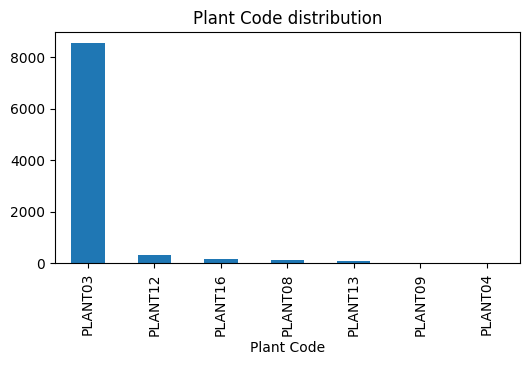

In [45]:
# Backup plot: concentration check for Plant Code
data['OrderList']['Plant Code'].value_counts().plot(kind='bar', figsize=(6,3), title='Plant Code distribution')


<Axes: title={'center': 'Origin Port distribution'}, xlabel='Origin Port'>

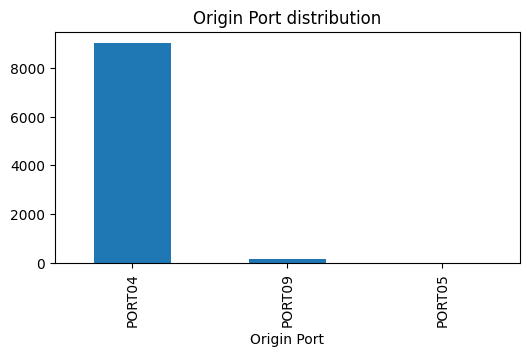

In [47]:
# Backup plot: concentration check for Origin Port
data['OrderList']['Origin Port'].value_counts().plot(kind='bar', figsize=(6,3), title='Origin Port distribution')

### Finding: Plant Code and Origin/Destination Port are too concentrated

| Dimension | Unique | Top share | Suitability |
|---|---|---|---|
| Plant Code | 7 | 92.7% (PLANT03) | not suitable |
| Origin Port | 3 | 98.1% (PORT04) | not suitable |
| Destination Port | 1 | 100% | no variance |
| **Customer** | **46** | ~10.6% | **suitable** |
| Product ID | 772 | ~2.1% | too granular for primary ranking |
| Carrier | 3 | 68.0% | suitable as filter/breakdown |

**Decision:** The Action Priority Index will be aggregated at the **Customer level** (46 units, reasonably distributed). Plant, Carrier, and Product serve as secondary filter/drill-down dimensions in the dashboard.

## 5b. Range & outlier check: inputs to the upcoming KPIs

The raw columns feeding each KPI require an explicit sanity check beyond the global null/duplicate check in Section 2, since zero-inflation, negative values, or out-of-range values would distort the KPI calculation without ever triggering a missing-value flag.

In [34]:
# --- Delivery Reliability inputs: Ship ahead / Ship late day count ---
for col in ['Ship ahead day count', 'Ship Late Day count']:
    s = order[col]
    print(f"{col:25s} | min: {s.min():6.1f} | max: {s.max():6.1f} | "
          f"mean: {s.mean():5.2f} | zeros: {(s == 0).sum():5d} ({(s == 0).mean():.1%}) | "
          f"negative: {(s < 0).sum()}")

Ship ahead day count      | min:    0.0 | max:    6.0 | mean:  1.85 | zeros:  4426 (48.0%) | negative: 0
Ship Late Day count       | min:    0.0 | max:    6.0 | mean:  0.04 | zeros:  9023 (97.9%) | negative: 0


<Axes: ylabel='Frequency'>

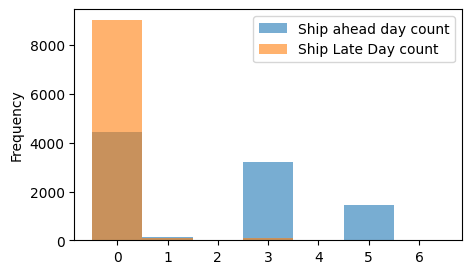

In [40]:
# Backup plot: outlier check via boxplot
import numpy as np
order[['Ship ahead day count', 'Ship Late Day count']].plot(
    kind='hist', bins=np.arange(-0.5, 7.5, 1), alpha=0.6, figsize=(5,3)
)

**Finding:** Ship ahead day count ranges from 0 to 6 (mean 1.85), with no negative values; 48.0% of orders are exactly 0. Ship Late Day count ranges from 0 to 6 (mean 0.04), with no negative values and 97.9% exactly 0. Both columns are well-formed on their own.

However, 123 orders (1.3%) show a value **greater than 0 in both columns simultaneously** — logically inconsistent, since an order cannot be both ahead of and behind schedule at the same time. This is a genuine data-quality anomaly (not a missing value or duplicate) and is flagged here rather than silently correct.

In [22]:
# --- Outlier flag via IQR for both columns ---
for col in ['Ship ahead day count', 'Ship Late Day count']:
    s = order[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lower) | (s > upper)).sum()
    print(f"{col:25s} | IQR bounds: [{lower:.1f}, {upper:.1f}] | outliers: {n_out} ({n_out/len(s):.1%})")

Ship ahead day count      | IQR bounds: [-4.5, 7.5] | outliers: 0 (0.0%)
Ship Late Day count       | IQR bounds: [0.0, 0.0] | outliers: 192 (2.1%)


**Finding:** Ship ahead day count has 0% IQR outliers — the entire 0–6 range fits inside the IQR bounds. Ship Late Day count shows 192 orders (2.1%) flagged as IQR outliers, but this is a mechanical artifact of extreme zero-inflation (97.9% zeros compresses the IQR to [0, 0]), not genuine noise. These 192 orders are exactly the *late* deliveries — the most business-relevant signal for a Delivery Reliability KPI — and must not be excluded as statistical outliers.

Both columns exhibit a non-continuous value profile (Ship ahead: 0, 1, 3, 5, 6; Ship Late: 0, 1, 3, 6)—rather than a uniform range from 0 to 6. This indicates that the underlying planning logic operates in discrete steps rather than on a daily granularity basis. This must be taken into account when defining daily thresholds for the planned delivery reliability metric.

In [ ]:
# General sanity: zero/negative Unit quantity or Weight ---
for col in ['Unit quantity', 'Weight']:
    s = order[col]
    print(f"{col:15s} | zeros: {(s == 0).sum()} | negative: {(s < 0).sum()} | min: {s.min()} | max: {s.max()}")

Unit quantity   | zeros: 0 | negative: 0 | min: 235 | max: 561847
Weight          | zeros: 2 | negative: 0 | min: 0.0 | max: 2338.4051259623893


**Finding:** Unit quantity has no zero or negative values (range 235–561,847). Weight has no negative values, but **2 orders (0.02%)** show a Weight of exactly 0 despite a valid, positive Unit quantity (348 and 361 units respectively) — a physically implausible combination that points to a data entry error rather than a genuine zero-weight shipment. These 2 records are removed in Section 7 below.

In [23]:
# Freight Cost inputs: does order weight fall within any FreightRates weight bracket? ---
def weight_in_any_bracket(w, brackets):
    return ((brackets['minm_wgh_qty'] <= w) & (w <= brackets['max_wgh_qty'])).any()

brackets = freight[['minm_wgh_qty', 'max_wgh_qty']].drop_duplicates()

order_costable['weight_in_range'] = order_costable['Weight'].apply(
    lambda w: weight_in_any_bracket(w, brackets)
)

n_out_of_range = (~order_costable['weight_in_range']).sum()
print(f"Orders with weight outside all FreightRates brackets: "
      f"{n_out_of_range} of {len(order_costable)} ({n_out_of_range/len(order_costable):.1%})")

Orders with weight outside all FreightRates brackets: 0 of 8361 (0.0%)


**Finding:** All 8,361 cost-eligible orders (100%) fall within at least one FreightRates weight bracket. The brackets span 0–99,999.99, comfortably covering the full order weight range of 0–2,338.41. The weight dimension is clean for the Freight Cost Exposure KPI — no order weight falls outside the defined rate structure.

## 6. Capacity logic: temporal framing

**Finding (authors' FAQ):**
> "The OrderList contains historical records of how the orders were routed and demand satisfied. The WhCapacities and rest of the tables are the current state constraints of the network."

**Consequence:** Comparing historical order volume (OrderList) against current capacity (WhCapacities) mixes two points in time. This is not concealed in the write-up but framed as a strength: the model tests how much pressure historical demand would place on *today's* network constraints — a forward-looking stress test rather than a retrospective utilization report. `WhCapacities` also measures **number of orders/day**, not weight or units — the capacity KPI must therefore be based on order counts, not weight sums.

## 6b. Join-key consistency: OrderList ↔ WhCapacities (Plant Code)

Analogous to the OrderList ↔ FreightRates key check in Section 4: before the Capacity Risk KPI can compare historical order volume against current warehouse capacity, the join key (Plant Code) needs to be validated between the two tables. An unmatched Plant Code would silently drop orders from the capacity-risk calculation without any warning.

In [25]:
wh_cap = data['WhCapacities']

plants_orders = set(order['Plant Code'].unique())
plants_capacity = set(wh_cap['Plant ID'].unique())

print("Plant Codes in OrderList:   ", sorted(plants_orders))
print("Plant Codes in WhCapacities:", sorted(plants_capacity))
print()
print("In OrderList but missing from WhCapacities:", sorted(plants_orders - plants_capacity))
print("In WhCapacities but unused in OrderList:    ", sorted(plants_capacity - plants_orders))

Plant Codes in OrderList:    ['PLANT03', 'PLANT04', 'PLANT08', 'PLANT09', 'PLANT12', 'PLANT13', 'PLANT16']
Plant Codes in WhCapacities: ['PLANT01', 'PLANT02', 'PLANT03', 'PLANT04', 'PLANT05', 'PLANT06', 'PLANT07', 'PLANT08', 'PLANT09', 'PLANT10', 'PLANT11', 'PLANT12', 'PLANT13', 'PLANT14', 'PLANT15', 'PLANT16', 'PLANT17', 'PLANT18', 'PLANT19']

In OrderList but missing from WhCapacities: []
In WhCapacities but unused in OrderList:     ['PLANT01', 'PLANT02', 'PLANT05', 'PLANT06', 'PLANT07', 'PLANT10', 'PLANT11', 'PLANT14', 'PLANT15', 'PLANT17', 'PLANT18', 'PLANT19']


**Finding:** All 7 Plant Codes used in OrderList (PLANT03, 04, 08, 09, 12, 13, 16) have a matching entry in WhCapacities. WhCapacities additionally lists 12 plants that never appear in OrderList — unused network capacity in this snapshot, not a data-quality issue. No orders are lost to a Plant Code mismatch, so no exclusion is required here.

In [26]:
# Share of orders affected, if any mismatch exists
unmatched_plants = plants_orders - plants_capacity
if unmatched_plants:
    n_affected = order['Plant Code'].isin(unmatched_plants).sum()
    print(f"Orders affected by unmatched Plant Code: {n_affected} of {len(order)} ({n_affected/len(order):.1%})")
else:
    print("All Plant Codes in OrderList have a matching entry in WhCapacities. No action needed.")

All Plant Codes in OrderList have a matching entry in WhCapacities. No action needed.


## 7. Data cleaning: removing duplicates and invalid records

Two data-quality issues identified above are resolved directly in this notebook, ensuring the KPI calculations are based on clean, deduplicated tables.

| Table | Issue | Action |
|---|---|---|
| FreightRates | 3 fully duplicated rate rows (2 duplicate groups) | `drop_duplicates()` |
| OrderList | 2 orders with Weight = 0 despite a valid, positive Unit quantity | Removed |

The 123 orders with both Ship ahead day count > 0 and Ship Late Day count > 0 (Section 5b) are **not** removed here. This is a logical inconsistency, not a null value or a duplicate, and clearing it silently would hide a signal that may still need investigation.

In [27]:
freight_clean = freight.drop_duplicates().reset_index(drop=True)
print(f"FreightRates: {len(freight)} -> {len(freight_clean)} rows "
      f"({len(freight) - len(freight_clean)} duplicate rows removed)")

order_clean = order[order['Weight'] > 0].copy()
print(f"OrderList: {len(order)} -> {len(order_clean)} rows "
      f"({len(order) - len(order_clean)} zero-weight orders removed)")

FreightRates: 1540 -> 1537 rows (3 duplicate rows removed)
OrderList: 9215 -> 9213 rows (2 zero-weight orders removed)


In [28]:
print("Remaining duplicate rows in FreightRates:", freight_clean.duplicated().sum())
print("Remaining zero-weight orders in OrderList:", (order_clean['Weight'] == 0).sum())

Remaining duplicate rows in FreightRates: 0
Remaining zero-weight orders in OrderList: 0


## 8. Writing tables to DBeaver (schema: thomasrabe)

All seven tables (five untouched, two cleaned) are written directly to the my schema via SQLAlchemy.

In [ ]:
# DBeaver connection setup
from dotenv import dotenv_values
from sqlalchemy import create_engine

config = dotenv_values()
pg_user = config['POSTGRES_USER']
pg_pass = config['POSTGRES_PASS']
pg_host = config['POSTGRES_HOST']
pg_port = config['POSTGRES_PORT']
pg_db   = config['POSTGRES_DB']
pg_schema = config['POSTGRES_SCHEMA']

url = f'postgresql://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_db}'
engine = create_engine(url, connect_args={"options": f"-csearch_path={pg_schema}"})

In [ ]:
# Write all 7 tables to Postgres
tables_raw = ['WhCosts', 'WhCapacities', 'ProductsPerPlant', 'VmiCustomers', 'PlantPorts']

for name in tables_raw:
data[name].to_sql(name.lower(), engine, if_exists='replace', index=False)

order_clean.to_sql('order_list', engine, if_exists='replace', index=False)
freight_clean.to_sql('freight_rates', engine, if_exists='replace', index=False)


All 7 tables written to Postgres schema: s_thomasrabe


## 9. Summary of decisions from this notebook

| # | Finding | Decision |
|---|---|---|
| 1 | Only 1 date across the whole dataset | Snapshot model instead of trend analysis; trend KPI dropped |
| 2 | CRF/V44_3 has no freight rate (854 orders, 9.3%) | Excluded from cost-exposure calculation, backed by authors' source |
| 3 | Plant/Port extremely concentrated (92–100%) | Aggregation level = **Customer** instead of Plant/Port |
| 4 | WhCapacities = current state, OrderList = historical | Framed as "historical demand vs. current constraints" (stress test) |
| 5 | WhCapacities counts orders, not weight/units | Capacity KPI calculated on an order-count basis |
| 6 | 123 orders (1.3%) flagged both ship-ahead and ship-late > 0; 192 orders (2.1%) are late deliveries (correctly not IQR-excluded) | Ship-ahead/late anomaly kept and flagged, not removed; late deliveries retained as the core reliability signal |
| 7 | All order weights fall within FreightRates brackets; all Plant Codes match WhCapacities | No exclusions needed for either join |
| 8 | FreightRates had 3 duplicate rows; OrderList had 2 zero-weight orders with positive quantity | Both removed (`freight_clean`, `order_clean`) |
